# Task 1 - Sales Forecasting System

Sqrock IT Solutions - Data Science Internship - Phase 1

Goal: analyse historical sales and forecast future sales with machine learning.

Pipeline (per the internship brief):
  1. Data Collection      -> real "Store Sales" dataset (Favorita / Kaggle mirror on Hugging Face)
  2. Data Cleaning        -> parse dates, handle missing values, remove duplicates
  3. EDA                  -> trend, best/worst months, seasonality, day-of-week
  4. Feature Engineering  -> Year / Month / Day + time-series lags & rolling means
  5. Model Building       -> Linear Regression, Decision Tree, Random Forest (+ ARIMA)
  6. Prediction           -> next 30 days forward forecast
  7. Evaluation           -> MAE, RMSE

Script version: sales_forecasting.py

In [1]:
import os
__file__ = os.path.abspath("sales_forecasting.py")  # run from the task folder; lets the script's relative paths resolve

In [2]:
from __future__ import annotations

import json
import os
import warnings

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings("ignore")

HERE = os.path.dirname(os.path.abspath(__file__))
DATA = os.path.join(HERE, "..", "data")
ART = os.path.join(HERE, "artifacts")
WEB = os.path.join(HERE, "..", "web", "assets")
os.makedirs(ART, exist_ok=True)
os.makedirs(WEB, exist_ok=True)

PALETTE = {"primary": "#2563eb", "accent": "#f59e0b", "danger": "#ef4444",
           "green": "#10b981", "purple": "#8b5cf6", "slate": "#64748b"}
plt.rcParams.update({"figure.dpi": 130, "font.size": 10, "axes.grid": True,
                     "grid.alpha": 0.25, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.autolayout": True})


def save(fig, name):
    for d in (ART, WEB):
        fig.savefig(os.path.join(d, name), bbox_inches="tight", facecolor="white")
    plt.close(fig)
    print(f"  [chart] {name}")

In [3]:
# Show every chart inline as well as saving it to artifacts/
from IPython.display import Image, display
_save_to_disk = save
def save(fig, name):
    _save_to_disk(fig, name)
    display(Image(os.path.join(ART, name)))

## 1. Collect

In [4]:
print("STEP 1 - Data collection")
raw = pd.read_csv(os.path.join(DATA, "store_sales_train.csv"))
stores = pd.read_csv(os.path.join(DATA, "store_sales_stores.csv"))
print(f"  raw rows={len(raw):,}  columns={list(raw.columns)}")
print(f"  date range {raw['date'].min()} -> {raw['date'].max()}")

STEP 1 - Data collection


  raw rows=3,000,888  columns=['id', 'date', 'store_nbr', 'family', 'sales', 'onpromotion']
  date range 2013-01-01 -> 2017-08-15


## 2. Clean

In [5]:
print("STEP 2 - Data cleaning")
df = raw.copy()
df["date"] = pd.to_datetime(df["date"], errors="coerce")
before = len(df)
df = df.dropna(subset=["date", "sales"])
df = df.drop_duplicates()
df["sales"] = pd.to_numeric(df["sales"], errors="coerce").fillna(0.0)
print(f"  dropped {before - len(df):,} bad/duplicate rows")

# Aggregate the transaction-level table to a clean daily time series
daily = (df.groupby("date", as_index=False)
           .agg(sales=("sales", "sum"), onpromotion=("onpromotion", "sum")))
daily = daily.sort_values("date").reset_index(drop=True)
# Reindex on a complete calendar so gaps are explicit, then impute sensibly
full_idx = pd.date_range(daily["date"].min(), daily["date"].max(), freq="D")
daily = daily.set_index("date").reindex(full_idx)
miss = int(daily["sales"].isna().sum())
daily["sales"] = daily["sales"].interpolate(method="time").ffill().bfill()
daily["onpromotion"] = daily["onpromotion"].fillna(0)
daily = daily.rename_axis("date").reset_index()
print(f"  daily series: {len(daily)} days, imputed {miss} gap(s), "
      f"missing now = {int(daily['sales'].isna().sum())}")

STEP 2 - Data cleaning


  dropped 0 bad/duplicate rows
  daily series: 1688 days, imputed 4 gap(s), missing now = 0


## 3. Eda

STEP 3 - Exploratory data analysis


  [chart] t1_trend.png


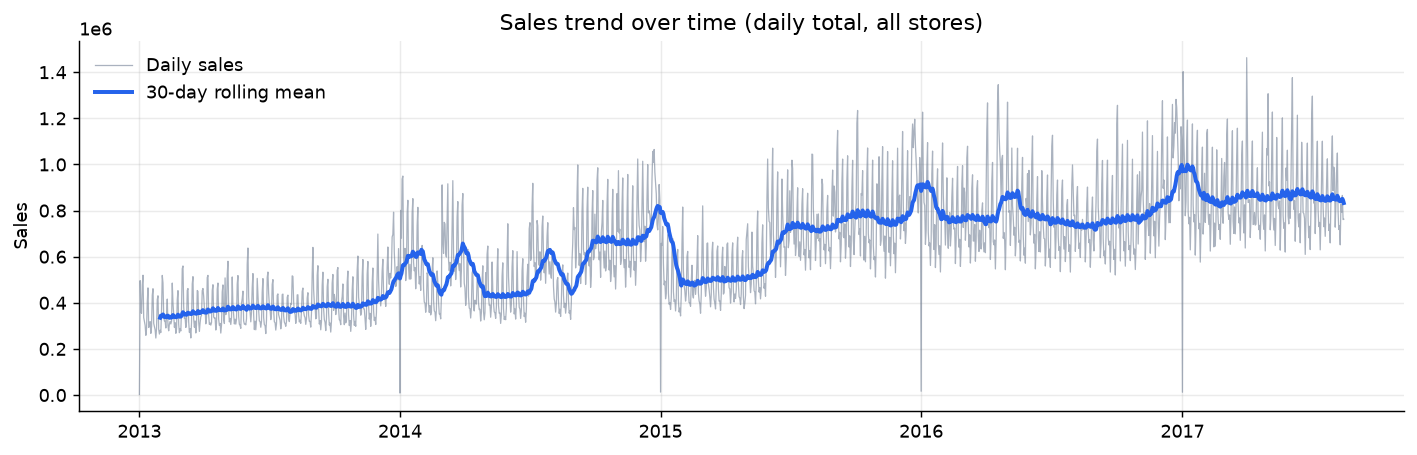

  [chart] t1_monthly.png


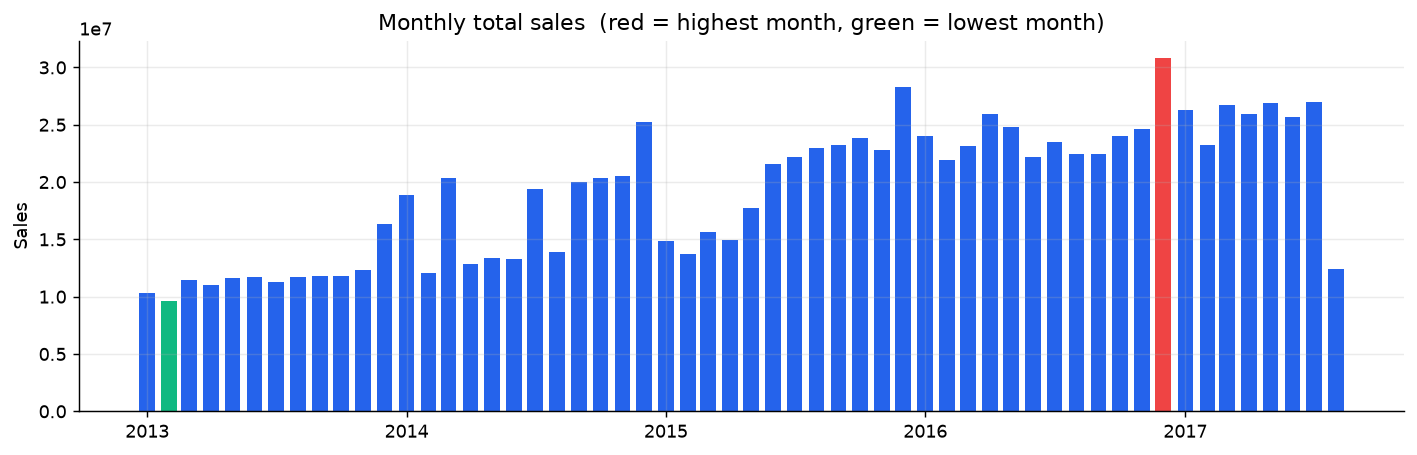

  highest month: 2016-12 (30,780,092)
  lowest  month: 2013-02 (9,658,960)


  [chart] t1_seasonality.png


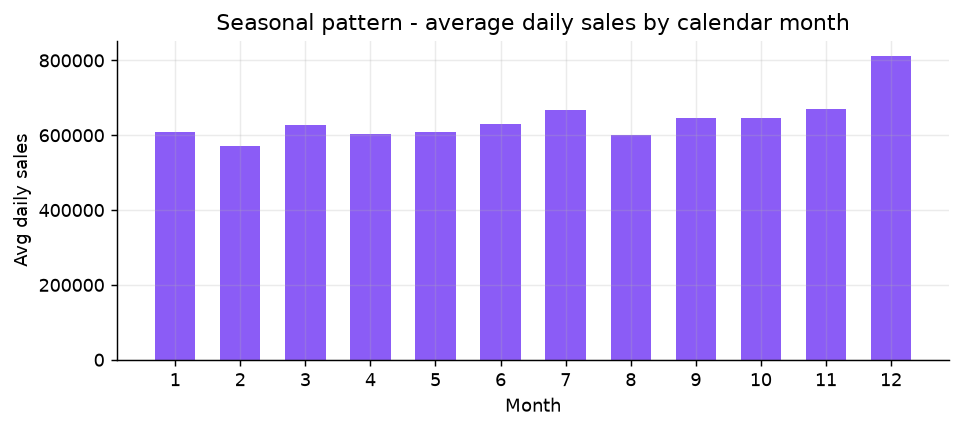

  [chart] t1_dow.png


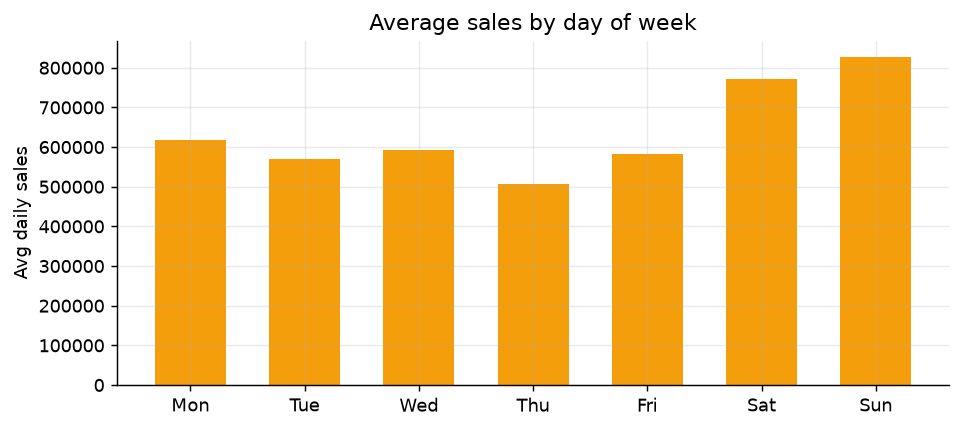

In [6]:
print("STEP 3 - Exploratory data analysis")
daily["year"] = daily["date"].dt.year
daily["month"] = daily["date"].dt.month
daily["month_name"] = daily["date"].dt.strftime("%b")
daily["dayofweek"] = daily["date"].dt.dayofweek
daily["dow_name"] = daily["date"].dt.strftime("%a")

# 3a. overall trend
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(daily["date"], daily["sales"], lw=0.7, color=PALETTE["slate"], alpha=0.55,
        label="Daily sales")
ax.plot(daily["date"], daily["sales"].rolling(30).mean(), lw=2.2,
        color=PALETTE["primary"], label="30-day rolling mean")
ax.set_title("Sales trend over time (daily total, all stores)")
ax.set_ylabel("Sales"); ax.legend(frameon=False)
save(fig, "t1_trend.png")

# 3b. monthly totals
monthly = daily.groupby(daily["date"].dt.to_period("M"))["sales"].sum()
monthly.index = monthly.index.to_timestamp()
fig, ax = plt.subplots(figsize=(11, 3.6))
colors = [PALETTE["danger"] if v == monthly.max() else
          PALETTE["green"] if v == monthly.min() else PALETTE["primary"] for v in monthly.values]
ax.bar(monthly.index, monthly.values, width=22, color=colors)
ax.set_title("Monthly total sales  (red = highest month, green = lowest month)")
ax.set_ylabel("Sales")
save(fig, "t1_monthly.png")

best, worst = monthly.idxmax(), monthly.idxmin()
print(f"  highest month: {best:%Y-%m} ({monthly.max():,.0f})")
print(f"  lowest  month: {worst:%Y-%m} ({monthly.min():,.0f})")

# 3c. seasonality by calendar month
season = daily.groupby("month")["sales"].mean()
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.bar(season.index, season.values, color=PALETTE["purple"], width=0.62)
ax.set_title("Seasonal pattern - average daily sales by calendar month")
ax.set_xlabel("Month"); ax.set_ylabel("Avg daily sales"); ax.set_xticks(range(1, 13))
save(fig, "t1_seasonality.png")

# 3d. day-of-week pattern
dow = daily.groupby("dayofweek")["sales"].mean()
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], dow.values,
       color=PALETTE["accent"], width=0.62)
ax.set_title("Average sales by day of week")
ax.set_ylabel("Avg daily sales")
save(fig, "t1_dow.png")

## 4. Features

In [7]:
print("STEP 4 - Feature engineering")
feat = daily.copy()
feat["day"] = feat["date"].dt.day
feat["dayofyear"] = feat["date"].dt.dayofyear
feat["weekofyear"] = feat["date"].dt.isocalendar().week.astype(int)
feat["is_weekend"] = (feat["dayofweek"] >= 5).astype(int)
for lag in (1, 7, 14, 30):
    feat[f"lag_{lag}"] = feat["sales"].shift(lag)
feat["roll_7"] = feat["sales"].shift(1).rolling(7).mean()
feat["roll_30"] = feat["sales"].shift(1).rolling(30).mean()
feat = feat.dropna().reset_index(drop=True)
print(f"  feature table: {feat.shape[0]} rows x {feat.shape[1]} cols")

FEATURES = ["year", "month", "day", "dayofweek", "dayofyear", "weekofyear",
            "is_weekend", "onpromotion", "lag_1", "lag_7", "lag_14", "lag_30",
            "roll_7", "roll_30"]

HORIZON = 90                      # hold-out window for evaluation
train = feat.iloc[:-HORIZON]
test = feat.iloc[-HORIZON:]
X_tr, y_tr = train[FEATURES], train["sales"]
X_te, y_te = test[FEATURES], test["sales"]
print(f"  train={len(train)} days | test={len(test)} days (time-based split)")

STEP 4 - Feature engineering
  feature table: 1658 rows x 18 cols
  train=1568 days | test=90 days (time-based split)


## 5. Models

In [8]:
print("STEP 5 - Model building")
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=10, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=300, max_depth=18,
                                           min_samples_leaf=2, random_state=42, n_jobs=-1),
}
results, preds = {}, {}
for name, mdl in models.items():
    mdl.fit(X_tr, y_tr)
    p = mdl.predict(X_te)
    preds[name] = p
    mae = mean_absolute_error(y_te, p)
    rmse = float(np.sqrt(mean_squared_error(y_te, p)))
    results[name] = {"MAE": round(mae, 2), "RMSE": round(rmse, 2)}
    print(f"  {name:18s} MAE={mae:10.2f}  RMSE={rmse:10.2f}")

# Optional advanced: ARIMA on the univariate series
try:
    from statsmodels.tsa.arima.model import ARIMA
    y_full = feat["sales"].values
    tr_ar, te_ar = y_full[:-HORIZON], y_full[-HORIZON:]
    arima = ARIMA(tr_ar, order=(7, 1, 1)).fit()
    p_ar = np.asarray(arima.forecast(steps=HORIZON))
    preds["ARIMA"] = p_ar
    mae = mean_absolute_error(te_ar, p_ar)
    rmse = float(np.sqrt(mean_squared_error(te_ar, p_ar)))
    results["ARIMA"] = {"MAE": round(mae, 2), "RMSE": round(rmse, 2)}
    print(f"  {'ARIMA(7,1,1)':18s} MAE={mae:10.2f}  RMSE={rmse:10.2f}")
except Exception as e:  # pragma: no cover
    print("  ARIMA skipped:", str(e)[:80])

best_model = min(results, key=lambda k: results[k]["RMSE"])
print(f"  --> best model by RMSE: {best_model}")

STEP 5 - Model building
  Linear Regression  MAE=  62115.72  RMSE=  82427.69
  Decision Tree      MAE=  71738.65  RMSE= 104803.82


  Random Forest      MAE=  46799.08  RMSE=  64170.54


  ARIMA(7,1,1)       MAE= 119375.41  RMSE= 148932.60
  --> best model by RMSE: Random Forest


## 6. Predict

STEP 6 - Prediction (actual vs predicted + 30-day forecast)


  [chart] t1_actual_vs_pred.png


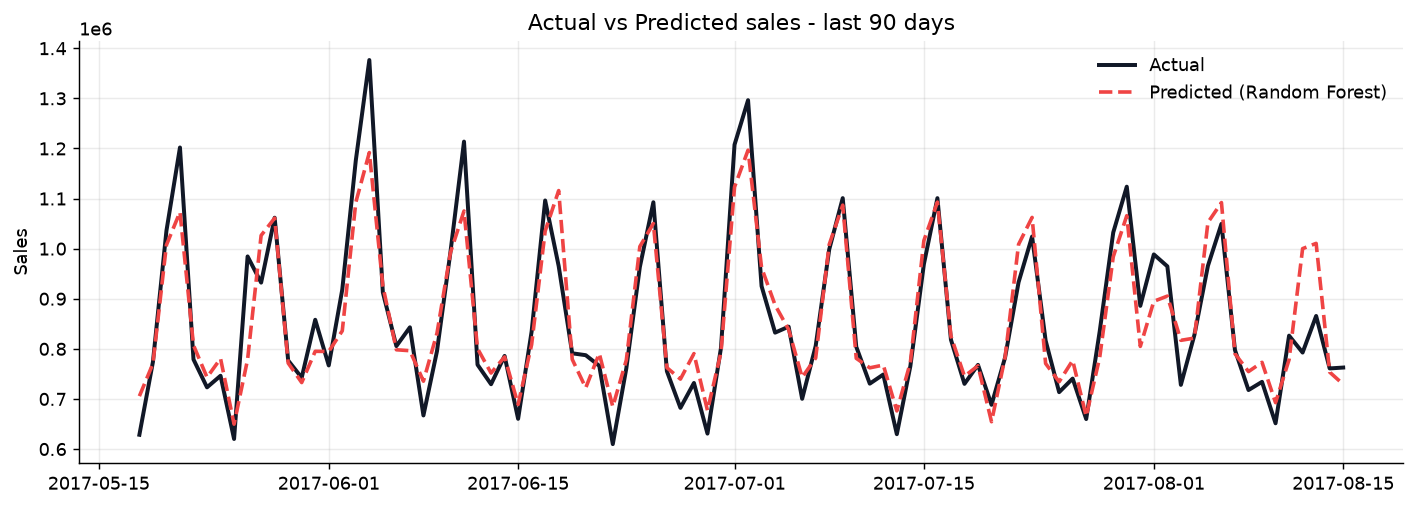

  [chart] t1_forecast.png


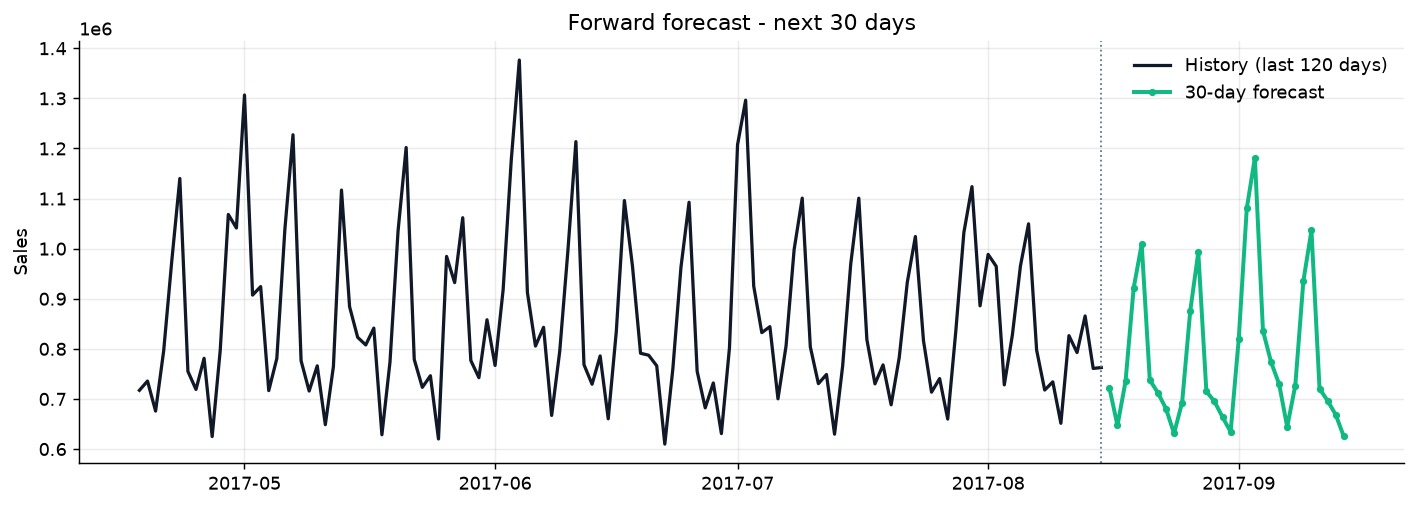

In [9]:
print("STEP 6 - Prediction (actual vs predicted + 30-day forecast)")

# 6a. actual vs predicted on the hold-out window
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(test["date"], y_te.values, color="#111827", lw=2.2, label="Actual")
ax.plot(test["date"], preds[best_model], color=PALETTE["danger"], lw=2.0,
        ls="--", label=f"Predicted ({best_model})")
ax.set_title(f"Actual vs Predicted sales - last {HORIZON} days")
ax.set_ylabel("Sales"); ax.legend(frameon=False)
save(fig, "t1_actual_vs_pred.png")

# 6b. recursive 30-day forward forecast with the best tree/linear model
rf = models[best_model]
history = feat[["date", "sales"]].copy()
fut_rows = []
future_dates = pd.date_range(feat["date"].max() + pd.Timedelta(days=1), periods=30, freq="D")
series = list(feat["sales"].values)
for d in future_dates:
    row = {
        "year": d.year, "month": d.month, "day": d.day, "dayofweek": d.dayofweek,
        "dayofyear": d.dayofyear, "weekofyear": int(d.isocalendar().week),
        "is_weekend": int(d.dayofweek >= 5), "onpromotion": float(np.mean(feat["onpromotion"])),
        "lag_1": series[-1], "lag_7": series[-7], "lag_14": series[-14],
        "lag_30": series[-30],
        "roll_7": float(np.mean(series[-7:])), "roll_30": float(np.mean(series[-30:])),
    }
    x = pd.DataFrame([row])[FEATURES]
    yhat = float(rf.predict(x)[0])
    fut_rows.append({"date": d, "forecast": yhat})
    series.append(yhat)
forecast = pd.DataFrame(fut_rows)

fig, ax = plt.subplots(figsize=(11, 4))
tail = feat.tail(120)
ax.plot(tail["date"], tail["sales"], color="#111827", lw=1.8, label="History (last 120 days)")
ax.plot(forecast["date"], forecast["forecast"], color=PALETTE["green"], lw=2.2,
        marker="o", ms=3, label="30-day forecast")
ax.axvline(feat["date"].max(), color=PALETTE["slate"], ls=":", lw=1)
ax.set_title("Forward forecast - next 30 days")
ax.set_ylabel("Sales"); ax.legend(frameon=False)
save(fig, "t1_forecast.png")

## 7. Eval + Save

In [10]:
print("STEP 7 - Evaluation & artifacts")
metrics = {
    "task": "Sales Forecasting System",
    "dataset": "Store Sales (Favorita grocery) - Kaggle mirror on Hugging Face",
    "records_raw": int(len(raw)),
    "daily_points": int(len(daily)),
    "date_range": [str(daily["date"].min().date()), str(daily["date"].max().date())],
    "train_days": int(len(train)), "test_days": int(len(test)),
    "features": FEATURES,
    "models": results,
    "best_model": best_model,
    "highest_month": f"{best:%Y-%m}", "highest_month_sales": round(float(monthly.max()), 2),
    "lowest_month": f"{worst:%Y-%m}", "lowest_month_sales": round(float(monthly.min()), 2),
    "forecast_next_30_days_total": round(float(forecast["forecast"].sum()), 2),
    "forecast_next_30_days_mean": round(float(forecast["forecast"].mean()), 2),
}
with open(os.path.join(ART, "metrics.json"), "w") as f:
    json.dump(metrics, f, indent=2)
forecast.to_csv(os.path.join(ART, "forecast_30d.csv"), index=False)
cmp = pd.DataFrame({"date": test["date"].dt.strftime("%Y-%m-%d"),
                    "actual": y_te.values.round(2),
                    "predicted": np.round(preds[best_model], 2)})
cmp.to_csv(os.path.join(ART, "actual_vs_predicted.csv"), index=False)
monthly.reset_index().rename(columns={"index": "month", "sales": "total_sales"}).to_csv(
    os.path.join(ART, "monthly_totals.csv"), index=False)

# compact payload for the web UI
web_payload = {
    "metrics": metrics,
    "trend": {"dates": daily["date"].dt.strftime("%Y-%m-%d").tolist(),
              "sales": daily["sales"].round(1).tolist()},
    "monthly": {"labels": [f"{d:%Y-%m}" for d in monthly.index],
                "values": monthly.round(1).tolist()},
    "seasonality": {"labels": list(range(1, 13)), "values": season.round(1).tolist()},
    "dow": {"labels": ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"],
            "values": dow.round(1).tolist()},
    "avp": {"dates": test["date"].dt.strftime("%Y-%m-%d").tolist(),
            "actual": y_te.round(1).tolist(),
            "predicted": np.round(preds[best_model], 1).tolist()},
    "forecast": {"dates": forecast["date"].dt.strftime("%Y-%m-%d").tolist(),
                 "values": forecast["forecast"].round(1).tolist(),
                 "history_dates": tail["date"].dt.strftime("%Y-%m-%d").tolist(),
                 "history_values": tail["sales"].round(1).tolist()},
}
with open(os.path.join(WEB, "t1_data.json"), "w") as f:
    json.dump(web_payload, f)

print("\n  RESULTS")
for k, v in results.items():
    print(f"    {k:18s} MAE={v['MAE']:>10}  RMSE={v['RMSE']:>10}")
print(f"  best={best_model} | 30-day forecast total={metrics['forecast_next_30_days_total']:,.0f}")
print("TASK 1 COMPLETE")

STEP 7 - Evaluation & artifacts

  RESULTS
    Linear Regression  MAE=  62115.72  RMSE=  82427.69
    Decision Tree      MAE=  71738.65  RMSE= 104803.82
    Random Forest      MAE=  46799.08  RMSE=  64170.54
    ARIMA              MAE= 119375.41  RMSE=  148932.6
  best=Random Forest | 30-day forecast total=23,539,632
TASK 1 COMPLETE
